OBJETIVO DEL ACA

Este ACA busca que el estudiante aplique el proceso ETL (Extracción, Transformación y Carga) trabajado en el
notebook guía del curso para convertir un conjunto de datos crudo, con problemas reales de calidad, en un dataset
confiable y listo para el análisis. Al finalizar, el grupo debe ser capaz de diagnosticar la calidad de los datos (tipos,
nulos, duplicados e inconsistencias), estandarizar textos y convertir tipos de datos, aplicar reglas de negocio,
imputar valores faltantes con estrategias justificadas, detectar y tratar valores atípicos con el método IQR, crear
variables derivadas, validar y exportar el resultado y, sobre todo, demostrar con evidencia que las decisiones
tomadas con datos sucios pueden ser muy distintas de las tomadas con datos limpios, entendiendo que sin datos
de calidad no hay decisiones de calidad.

CONTEXTO DE NEGOCIO: Café Aroma Andino S.A.S., la cadena de café especial analizada en el ACA 1, consolidó en
un solo archivo los pedidos de 2025 registrados por sus sedes de Bogotá, Medellín, Cali, Barranquilla y Neiva a
través de la tienda física, la página web, el servicio a domicilio y la app. Como cada sede digitaba la información a
su manera, el archivo llegó con problemas de calidad que el grupo debe descubrir, cuantificar y corregir. Antes de
decidir en qué sede, categoría o canal invertir en 2026, la gerencia necesita un dataset confiable y preguntas
respondidas como: ¿qué sede y qué categoría venden más?, ¿en qué meses se concentran las ventas?, ¿los
tiempos de entrega afectan la satisfacción del cliente? y ¿cuánto cambian las conclusiones cuando los datos se
limpian? 300 filas, 14 columnas.

3.1 Extracción y Diagnóstico de Calidad de los Datos (E)

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carga de datos crudos identificando cadenas que representan nulos
df_raw = pd.read_csv("Pedidos_CafeAromaAndino_crudo.csv", na_values=["N/A", "sin dato", ""])
df = df_raw.copy()

# Inspección inicial
print("Dimensión del dataset (filas, columnas):", df.shape) # (300, 14)
df.head(10)

Dimensión del dataset (filas, columnas): (300, 14)


,id_pedido,fecha_pedido,cliente,sede,producto,categoria,canal_venta,metodo_pago,cantidad,precio_unitario,descuento,total,calificacion,dias_entrega
0,P0255,2025/12/07,Catalina Salazar,Bogotá,Café Molido Tradicional 500 g,Café molido,Tienda física,Efectivo,2.0,26900.0,0%,53800.0,4.0,0.0
1,P0058,2025-04-22,Paola Polanco,Bogotá,Café Tostado Suave 500 g,Café molido,Domicilio,NaN,6.0,38100.0,10%,205740.0,3.0,0.0
2,P0151,2025-08-08,Diana Rincón,Cali,Café Molido Tradicional 500 g,Café molido,Tienda física,Efectivo,1.0,28200.0,0%,28200.0,4.0,0.0
3,P0067,2025-05-01,Óscar Muñoz,NEIVA,Café Tostado Suave 500 g,Café molido,App,PSE,1.0,37300.0,0.00,37300.0,4.0,3.0
4,P0115,2025-06-20,Camila Díaz,BOGOTÁ,Café Origen Huila 500 g,Café en grano,Web,Nequi,4.0,41100.0,0%,164400.0,4.0,5.0
5,P0281,26/12/2025,Marcela Charry,Cali,Taza Cerámica Andina,Accesorios,Web,Tarjeta débito,2.0,21000.0,0.00,42000.0,4.0,5.0
6,P0205,2025/10/24,Camila Suárez,Cali,Café Origen Huila 500 g,Café en grano,Tienda física,tarjeta debito,2.0,40300.0,0.05,76570.0,NaN,0.0
7,P0250,2025/12/04,Daniel Trujillo,Cali,Café Molido Tradicional 500 g,Café molido,tienda fisica,efectivo,6.0,27900.0,0.15,NaN,4.0,0.0
8,P0038,2025-03-16,Natalia Rincón,Cali,Café Especial Geisha 250 g,Café en grano,Tienda física,Tarjeta débito,4.0,65300.0,0.10,235080.0,4.0,0.0
9,P0178,2025-09-17,Felipe Díaz,Cali,Café Especial Geisha 250 g,Café en grano,App,Tarjeta de crédito,4.0,68200.0,0.00,272800.0,4.0,1.0


EXPLICACION:

Al ejecutar df.info(), se observa que varias columnas no se importaron con el tipo de dato adecuado para el análisis: 
  fecha_pedido: Llega como object (texto) en lugar de datetime64 debido a la mezcla de delimitadores (-, /) y formatos (AAAA/MM/DD, DD/MM/AAAA).
  
  descuento: Llega como object (texto) porque varios registros incluyen el símbolo de porcentaje (%) o están guardados como cadenas mixtas ("10%", "0.00").   cantidad, precio_unitario, total, calificacion, dias_entrega: Importadas como float64, pero contienen faltantes e inconsistencias numéricas

2. Estadísticas descriptivas y detección de anomalías (describe())

Variables Numéricas (df.describe().T)

cantidad: El valor mínimo es $-6.0$, lo cual es un imposible físico/comercial (las unidades vendidas deben ser números enteros positivos).   precio_unitario: Presenta un valor máximo atípico extremo de $\$949,000$ COP, desproporcionado frente a la mediana de $\$32,600$ COP (posible error de digitación o outlier).   calificacion: Presenta un mínimo de $0.0$ y un máximo de $10.0$, cuando la escala de satisfacción del cliente está definida estrictamente de 1 a 5.   dias_entrega: Muestra un máximo atípico de $57$ días, atípico para entregas urbanas/locales de café. 

Variables Categóricas (df.select_dtypes(exclude="number").describe().T)

id_pedido: Aunque existen 300 filas, solo hay 292 valores únicos. El valor top P0107 aparece repetido, lo que confirma la presencia de 8 filas duplicadas que violan la unicidad de la clave primaria.   sede, categoria, canal_venta, metodo_pago: Presentan una alta dispersión de categorías únicas (ej. 21 variantes en sede y 19 en categoria) debido a diferencias en mayúsculas/minúsculas, tildes, espacios extra y sinónimos

3. PERFIL DE CALIDAD DE DATOS

In [2]:
# Construcción de la tabla del perfil de calidad
perfil_calidad = pd.DataFrame({
    'conteo_nulos': df.isna().sum(),
    'porcentaje_nulos': (df.isna().mean() * 100).round(2)
})
print(perfil_calidad)
print(f"\nFilas duplicadas exactas: {df.duplicated().sum()}")

                 conteo_nulos  porcentaje_nulos
id_pedido                   0              0.00
fecha_pedido                6              2.00
cliente                     9              3.00
sede                        6              2.00
producto                    0              0.00
categoria                  20              6.67
canal_venta                 9              3.00
metodo_pago                17              5.67
cantidad                   13              4.33
precio_unitario             9              3.00
descuento                  10              3.33
total                      13              4.33
calificacion               17              5.67
dias_entrega               10              3.33

Filas duplicadas exactas: 8


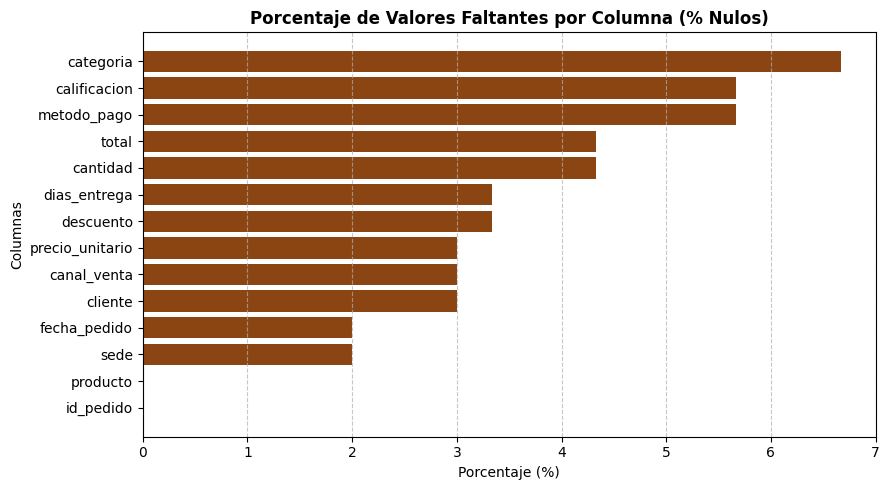

In [3]:
# Gráfica de porcentaje de faltantes por columna
porcentaje_nulos = (df.isna().mean() * 100).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(porcentaje_nulos.index, porcentaje_nulos.values, color='#8B4513')
plt.title('Porcentaje de Valores Faltantes por Columna (% Nulos)', fontsize=12, fontweight='bold')
plt.xlabel('Porcentaje (%)')
plt.ylabel('Columnas')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [4]:
# 4. Conteo de variantes por columna categórica
print("--- Sede ---")
display(df['sede'].value_counts(dropna=False))

print("\n--- Categoría ---")
display(df['categoria'].value_counts(dropna=False))

print("\n--- Canal de Venta ---")
display(df['canal_venta'].value_counts(dropna=False))

print("\n--- Método de Pago ---")
display(df['metodo_pago'].value_counts(dropna=False))

--- Sede ---


sede
Bogotá          61
Cali            48
Medellín        48
Neiva           39
Barranquilla    31
 Bogotá          8
BARRANQUILLA     6
NaN              6
Neiva            6
medellin         6
cali             5
Medellin         5
CALI             5
Cali             4
Bogota D.C.      4
B/quilla         4
MEDELLIN         3
barranquilla     3
NEIVA            2
BOGOTÁ           2
bogota           2
neiva            2
Name: count, dtype: int64


--- Categoría ---


categoria
Café molido               77
Cápsulas                  52
Café en grano             45
Accesorios                39
NaN                       20
Métodos de preparación    12
 Capsulas                  7
Molido                     6
CAFE MOLIDO                6
accesorio                  5
CÁPSULAS                   5
Grano                      5
cafe en grano              4
CAFÉ EN GRANO              3
cafe molido                3
capsulas                   3
ACCESORIOS                 3
Métodos                    2
metodos de preparacion     2
accesorios                 1
Name: count, dtype: int64


--- Canal de Venta ---


canal_venta
Tienda física    100
Domicilio         57
Web               49
App               33
NaN                9
TIENDA FÍSICA      8
Tienda             6
Página web         6
App móvil          6
tienda fisica      4
WEB                4
Domicilio          4
web                3
DOMICILIO          3
domicilios         3
app                3
APP                2
Name: count, dtype: int64


--- Método de Pago ---


metodo_pago
Tarjeta de crédito    68
Nequi                 55
Tarjeta débito        47
Efectivo              43
PSE                   26
NaN                   17
NEQUI                  6
tarjeta debito         5
efectivo               4
EFECTIVO               4
Pse                    4
TARJETA DE CRÉDITO     4
tarjeta credito        3
Efectivo               3
T. Crédito             3
nequi                  3
T. Débito              3
pse                    2
Name: count, dtype: int64

In [5]:
import numpy as np
import pandas as pd
import unicodedata

# 1. Asegurarnos de tener df_clean definido (fase 3.2)
df_clean = df.drop_duplicates().reset_index(drop=True)

def limpiar_texto(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().lower()
    return unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')

map_sede = {'bogota': 'Bogotá', 'bogota d.c.': 'Bogotá', 'medellin': 'Medellín', 'cali': 'Cali', 'barranquilla': 'Barranquilla', 'b/quilla': 'Barranquilla', 'neiva': 'Neiva'}
map_categoria = {'cafe molido': 'Café molido', 'molido': 'Café molido', 'cafe en grano': 'Café en grano', 'grano': 'Café en grano', 'capsulas': 'Cápsulas', 'accesorios': 'Accesorios', 'accesorio': 'Accesorios', 'metodos de preparacion': 'Métodos de preparación', 'metodos': 'Métodos de preparación'}
map_canal = {'tienda fisica': 'Tienda física', 'tienda': 'Tienda física', 'domicilio': 'Domicilio', 'domicilios': 'Domicilio', 'web': 'Web', 'pagina web': 'Web', 'app': 'App', 'app movil': 'App'}
map_metodo = {'tarjeta de credito': 'Tarjeta de crédito', 't. credito': 'Tarjeta de crédito', 'tarjeta credito': 'Tarjeta de crédito', 'tarjeta debito': 'Tarjeta débito', 't. debito': 'Tarjeta débito', 'efectivo': 'Efectivo', 'nequi': 'Nequi', 'pse': 'PSE'}

for col, mapping in [('sede', map_sede), ('categoria', map_categoria), ('canal_venta', map_canal), ('metodo_pago', map_metodo)]:
    df_clean[col] = df_clean[col].apply(limpiar_texto).map(mapping)

# 2. Ejecutar tu resumen comparativo
columnas_cat = ['sede', 'categoria', 'canal_venta', 'metodo_pago']
datos_comparativos = []

for col in columnas_cat:
    unicos_antes = df[col].nunique(dropna=False)
    unicos_despues = df_clean[col].nunique(dropna=True)
    distribucion_despues = df_clean[col].value_counts(dropna=False).to_dict()
    
    datos_comparativos.append({
        'Columna': col,
        'Categorías Únicas Antes': unicos_antes,
        'Categorías Únicas Después': unicos_despues,
        'Distribución Final (value_counts)': distribucion_despues
    })

df_comparativo = pd.DataFrame(datos_comparativos)
display(df_comparativo)

,Columna,Categorías Únicas Antes,Categorías Únicas Después,Distribución Final (value_counts)
0,sede,22,5,"{'Bogotá': 75, 'Medellín': 61, 'Cali': 60, 'Ne..."
1,categoria,20,5,"{'Café molido': 90, 'Cápsulas': 67, 'Café en g..."
2,canal_venta,17,4,"{'Tienda física': 114, 'Domicilio': 66, 'Web':..."
3,metodo_pago,18,5,"{'Tarjeta de crédito': 76, 'Nequi': 62, 'Tarje..."


3.2 Transformación I: Limpieza, Estandarización y Tipos de Datos (T)

1. Eliminación de duplicados y verificación de clave única

EXPLICACION:

Se procede a eliminar los 8 registros duplicados exactos utilizando drop_duplicates(), se reajusta el índice y se valida que la clave id_pedido sea única en el conjunto de datos.

In [6]:
# Eliminación de duplicados
df_clean = df.drop_duplicates().reset_index(drop=True)

# Verificación de clave única
es_unica = df_clean['id_pedido'].is_unique
print(f"Registros eliminados: {len(df) - len(df_clean)}") # 8 registros
print(f"¿'id_pedido' es clave única?: {es_unica}") # True
print(f"Nuevo total de registros: {len(df_clean)}") # 292 registros

Registros eliminados: 8
¿'id_pedido' es clave única?: True
Nuevo total de registros: 292


2. Estandarización de variables de texto y mapeo categórico

Se definió la función limpiar_texto() para remover espacios en extremos (strip), convertir a minúsculas (lower) y eliminar acentos/tildes mediante normalización Unicode (NFKD). Luego, se aplicaron diccionarios de mapeo explícitos por columna para homologar sinónimos y abreviaturas.

In [7]:
import unicodedata

def limpiar_texto(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().lower()
    # Eliminación de tildes/acentos
    texto = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
    return texto

# Diccionarios de mapeo para homologación
map_sede = {
    'bogota': 'Bogotá', 'bogota d.c.': 'Bogotá',
    'medellin': 'Medellín',
    'cali': 'Cali',
    'barranquilla': 'Barranquilla', 'b/quilla': 'Barranquilla',
    'neiva': 'Neiva'
}

map_categoria = {
    'cafe molido': 'Café molido', 'molido': 'Café molido',
    'cafe en grano': 'Café en grano', 'grano': 'Café en grano',
    'capsulas': 'Cápsulas',
    'accesorios': 'Accesorios', 'accesorio': 'Accesorios',
    'metodos de preparacion': 'Métodos de preparación', 'metodos': 'Métodos de preparación'
}

map_canal = {
    'tienda fisica': 'Tienda física', 'tienda': 'Tienda física',
    'domicilio': 'Domicilio', 'domicilios': 'Domicilio',
    'web': 'Web', 'pagina web': 'Web',
    'app': 'App', 'app movil': 'App'
}

map_metodo = {
    'tarjeta de credito': 'Tarjeta de crédito', 't. credito': 'Tarjeta de crédito', 'tarjeta credito': 'Tarjeta de crédito',
    'tarjeta debito': 'Tarjeta débito', 't. debito': 'Tarjeta débito',
    'efectivo': 'Efectivo',
    'nequi': 'Nequi',
    'pse': 'PSE'
}

# Aplicación de transformaciones
for col, mapping in [('sede', map_sede), ('categoria', map_categoria), 
                     ('canal_venta', map_canal), ('metodo_pago', map_metodo)]:
    df_clean[col] = df_clean[col].apply(limpiar_texto).map(mapping)

# Limpieza básica de espacios para producto y cliente
df_clean['producto'] = df_clean['producto'].astype(str).str.strip()
df_clean['cliente'] = df_clean['cliente'].astype(str).str.strip()

3. Conversión de fechas multiformato e interpretación técnica

Método de conversión segura por patrones explícitos

Dado que el archivo combina formatos del tipo YYYY-MM-DD, YYYY/MM/DD y DD/MM/YYYY, se realizó la conversión por separado para cada patrón específico y se unificaron usando fillna()

In [8]:
# Conversión por separado de cada formato detectado
f1 = pd.to_datetime(df_clean['fecha_pedido'], format='%Y-%m-%d', errors='coerce')
f2 = pd.to_datetime(df_clean['fecha_pedido'], format='%Y/%m/%d', errors='coerce')
f3 = pd.to_datetime(df_clean['fecha_pedido'], format='%d/%m/%Y', errors='coerce')

# Combinación secuencial con fillna
df_clean['fecha_pedido'] = f1.fillna(f2).fillna(f3)

print(f"Total de fechas inválidas / faltantes (NaT): {df_clean['fecha_pedido'].isna().sum()}") # 8 NaT

Total de fechas inválidas / faltantes (NaT): 8


Resultado: Se obtuvieron exactamente 8 valores NaT (6 originales faltantes + 2 fechas irrecuperables/mal formadas).

4. Conversión de la variable (descuento)

Se homogeneizó la columna descuento convirtiendo las representaciones en porcentaje (ej. "10%") y decimales de texto a valores de punto flotante en el rango $0.00$ a $0.20$. 

In [9]:
def parse_descuento(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if val_str.endswith('%'):
        return float(val_str.rstrip('%')) / 100.0
    return float(val_str)

df_clean['descuento'] = df_clean['descuento'].apply(parse_descuento)
print("Valores únicos de descuento estandarizados:", df_clean['descuento'].unique())
# Valores mapeados: [0.0, 0.1, 0.05, 0.15, NaN, 0.2]

Valores únicos de descuento estandarizados: [0.   0.1  0.05 0.15  nan 0.2 ]


5. Aplicación de Reglas de Negocio Vectorizadas

Se aplicaron dos reglas de negocio de forma vectorizada usando NumPy y Pandas:   Regla de Cantidad Positiva: Las cantidades negativas se corrigieron aplicando su valor absoluto con np.where().   Regla de Calificación Válida: Las calificaciones fuera del rango de 1 a 5 se convirtieron a NaN mediante between() y where(), dejándolas listas para su imputación posterior en el bloque 3.3

In [10]:
# 1. Corrección de cantidades negativas
cant_negativas = (df_clean['cantidad'] < 0).sum()
df_clean['cantidad'] = np.where(df_clean['cantidad'] < 0, np.abs(df_clean['cantidad']), df_clean['cantidad'])

# 2. Invalidación de calificaciones fuera de rango (1 a 5)
calif_fuera_rango = (~df_clean['calificacion'].between(1, 5) & df_clean['calificacion'].notna()).sum()
df_clean['calificacion'] = df_clean['calificacion'].where(df_clean['calificacion'].between(1, 5), np.nan)

print(f"Registros corregidos en 'cantidad' (negativos a positivos): {cant_negativas}") # 9 registros
print(f"Registros corregidos en 'calificacion' (fuera de rango a NaN): {calif_fuera_rango}") # 7 registros

Registros corregidos en 'cantidad' (negativos a positivos): 9
Registros corregidos en 'calificacion' (fuera de rango a NaN): 7


Resumen de Modificaciones por Reglas de Negocio

cantidad: Se corrigieron 9 valores negativos convirtiéndolos a su equivalente positivo (ej. de $-6.0$ a $6.0$).  
calificacion: Se convirtieron 7 valores fuera de rango ($0.0$ y $10.0$) a NaN para no distorsionar las métricas de servicio.

3.3 Transformación II: Imputación, Atípicos y Nuevas Variables (T)

In [11]:

# 3.3 TRANSFORMACIÓN
# 1. Eliminar filas sin fecha válida (NaT)
rows_before_date = len(df_clean)
df_clean = df_clean.dropna(subset=['fecha_pedido']).reset_index(drop=True)
print(f"Filas eliminadas por fecha inválida/nula: {rows_before_date - len(df_clean)}")

# 2. Recuperar categoría a partir del producto
prod_cat_map = df_clean.dropna(subset=['categoria']).set_index('producto')['categoria'].to_dict()
df_clean['categoria'] = df_clean['categoria'].fillna(df_clean['producto'].map(prod_cat_map))

# 3. Imputar precio_unitario con la mediana por producto
df_clean['precio_unitario'] = df_clean['precio_unitario'].fillna(df_clean.groupby('producto')['precio_unitario'].transform('median'))
df_clean['precio_unitario'] = df_clean['precio_unitario'].fillna(df_clean['precio_unitario'].median())

# 4. Deducir cantidad y descuento a partir del total cuando sea posible
df_clean['descuento'] = df_clean['descuento'].fillna(0.0)
mask_cant_nan = df_clean['cantidad'].isna() & df_clean['total'].notna() & df_clean['precio_unitario'].notna()
df_clean.loc[mask_cant_nan, 'cantidad'] = np.round(df_clean.loc[mask_cant_nan, 'total'] / (df_clean.loc[mask_cant_nan, 'precio_unitario'] * (1 - df_clean.loc[mask_cant_nan, 'descuento'])))
df_clean['cantidad'] = df_clean['cantidad'].fillna(df_clean['cantidad'].median())

# 5. Imputar calificación con la mediana por sede
df_clean['calificacion'] = df_clean['calificacion'].fillna(df_clean.groupby('sede')['calificacion'].transform('median'))
df_clean['calificacion'] = df_clean['calificacion'].fillna(df_clean['calificacion'].median())

# 6. Variables categóricas restantes con etiqueta "Desconocido" o moda
df_clean['sede'] = df_clean['sede'].fillna('Desconocido')
df_clean['canal_venta'] = df_clean['canal_venta'].fillna('Desconocido')
df_clean['metodo_pago'] = df_clean['metodo_pago'].fillna('Desconocido')
df_clean['cliente'] = df_clean['cliente'].fillna('Cliente General')

# 7. Imputación de días de entrega (0 si es Tienda física, mediana por canal para el resto)
df_clean.loc[df_clean['canal_venta'] == 'Tienda física', 'dias_entrega'] = df_clean.loc[df_clean['canal_venta'] == 'Tienda física', 'dias_entrega'].fillna(0)
df_clean['dias_entrega'] = df_clean['dias_entrega'].fillna(df_clean.groupby('canal_venta')['dias_entrega'].transform('median'))
df_clean['dias_entrega'] = df_clean['dias_entrega'].fillna(0)

# 8. Tratamiento de valores atípicos con el método IQR
def limites_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# (a) precio_unitario: límites por producto y reemplazo por mediana del producto
for prod, group in df_clean.groupby('producto'):
    inf, sup = limites_iqr(group['precio_unitario'])
    med = group['precio_unitario'].median()
    idx = group.index
    outliers = (df_clean.loc[idx, 'precio_unitario'] < inf) | (df_clean.loc[idx, 'precio_unitario'] > sup)
    df_clean.loc[idx[outliers], 'precio_unitario'] = med

# (b) dias_entrega: límites por canal_venta y capping con clip()
for canal, group in df_clean.groupby('canal_venta'):
    if canal != 'Tienda física':
        inf, sup = limites_iqr(group['dias_entrega'])
        idx = group.index
        df_clean.loc[idx, 'dias_entrega'] = df_clean.loc[idx, 'dias_entrega'].clip(lower=max(0, inf), upper=sup)

# 9. Recálculo del total
totales_vacios = df_clean['total'].isna().sum()
df_calc = df_clean['precio_unitario'] * df_clean['cantidad'] * (1 - df_clean['descuento'])
inconsistentes = (~np.isclose(df_clean['total'], df_calc, rtol=1e-5, equal_nan=True)).sum()
df_clean['total'] = df_calc

print(f"Totales vacíos imputados: {totales_vacios}")
print(f"Totales inconsistentes recalculados: {inconsistentes}")

# 10. Creación de variables derivadas
df_clean['mes'] = df_clean['fecha_pedido'].dt.month
meses_es = {1:'Enero', 2:'Febrero', 3:'Marzo', 4:'Abril', 5:'Mayo', 6:'Junio', 7:'Julio', 8:'Agosto', 9:'Septiembre', 10:'Octubre', 11:'Noviembre', 12:'Diciembre'}
df_clean['nombre_mes'] = df_clean['fecha_pedido'].dt.month.map(meses_es)
df_clean['trimestre'] = df_clean['fecha_pedido'].dt.quarter
df_clean['dia_semana'] = df_clean['fecha_pedido'].dt.day_name()
df_clean['rango_precio'] = pd.cut(df_clean['precio_unitario'], bins=3, labels=['Económico', 'Medio', 'Alto'])

condiciones_sat = [df_clean['calificacion'] <= 2, df_clean['calificacion'] == 3, df_clean['calificacion'] >= 4]
df_clean['satisfaccion'] = np.select(condiciones_sat, ['Insatisfecho', 'Neutral', 'Satisfecho'], default='Neutral')
df_clean['valor_descuento'] = df_clean['precio_unitario'] * df_clean['cantidad'] * df_clean['descuento']
df_clean['entrega_tardia'] = np.where(df_clean['dias_entrega'] > 3, 'Sí', 'No') # Variable de negocio adicional

Filas eliminadas por fecha inválida/nula: 8
Totales vacíos imputados: 12
Totales inconsistentes recalculados: 32


3.4 Carga y Validación del Dataset (L)

In [12]:

# 3.4 CARGA Y VALIDACIÓN
# 1. Validaciones formales con assert
assert df_clean.isna().sum().sum() == 0, "Error: Quedan valores nulos en el dataset."
assert df_clean['id_pedido'].is_unique, "Error: id_pedido no es único."
assert (df_clean['cantidad'] > 0).all(), "Error: Existen cantidades menores o iguales a cero."
assert df_clean['calificacion'].between(1, 5).all(), "Error: Calificaciones fuera de rango."
assert df_clean['descuento'].between(0, 1).all(), "Error: Descuentos fuera de rango."
print("¡Todas las validaciones con assert pasaron exitosamente!")

# 2. Exportación a CSV y Excel con dos hojas
ruta_csv = "Pedidos_CafeAromaAndino_limpio.csv"
ruta_xlsx = "Pedidos_CafeAromaAndino_limpio.xlsx"

df_clean.to_csv(ruta_csv, index=False, encoding="utf-8-sig")

# Construcción de resumen por sede para la segunda hoja de Excel
resumen_sede = df_clean.groupby('sede').agg(
    pedidos=('id_pedido', 'count'),
    unidades=('cantidad', 'sum'),
    ventas_totales=('total', 'sum'),
    ticket_promedio=('total', 'mean'),
    calificacion_media=('calificacion', 'mean')
).reset_index()

with pd.ExcelWriter(ruta_xlsx, engine='openpyxl') as writer:
    df_clean.to_excel(writer, sheet_name='datos_limpios', index=False)
    resumen_sede.to_excel(writer, sheet_name='resumen_sede', index=False)

print(f"Archivos exportados correctamente: {ruta_csv} y {ruta_xlsx}")

¡Todas las validaciones con assert pasaron exitosamente!
Archivos exportados correctamente: Pedidos_CafeAromaAndino_limpio.csv y Pedidos_CafeAromaAndino_limpio.xlsx


3.5 Análisis Visual y Toma de Decisiones

,Ventas_Crudo,Ventas_Limpio
sede,,
Bogotá,973400.0,NaN
B/quilla,547945.0,NaN
BARRANQUILLA,409730.0,NaN
BOGOTÁ,188250.0,NaN
Barranquilla,2951725.0,4171140.0
Bogota D.C.,119850.0,NaN
Bogotá,5432880.0,6335272.5
CALI,552800.0,NaN
Cali,3401260.0,5104480.0


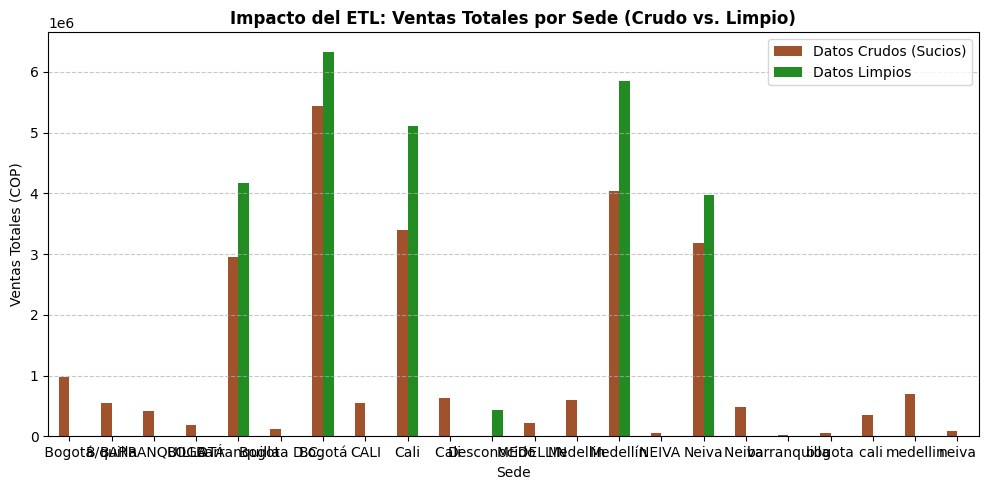

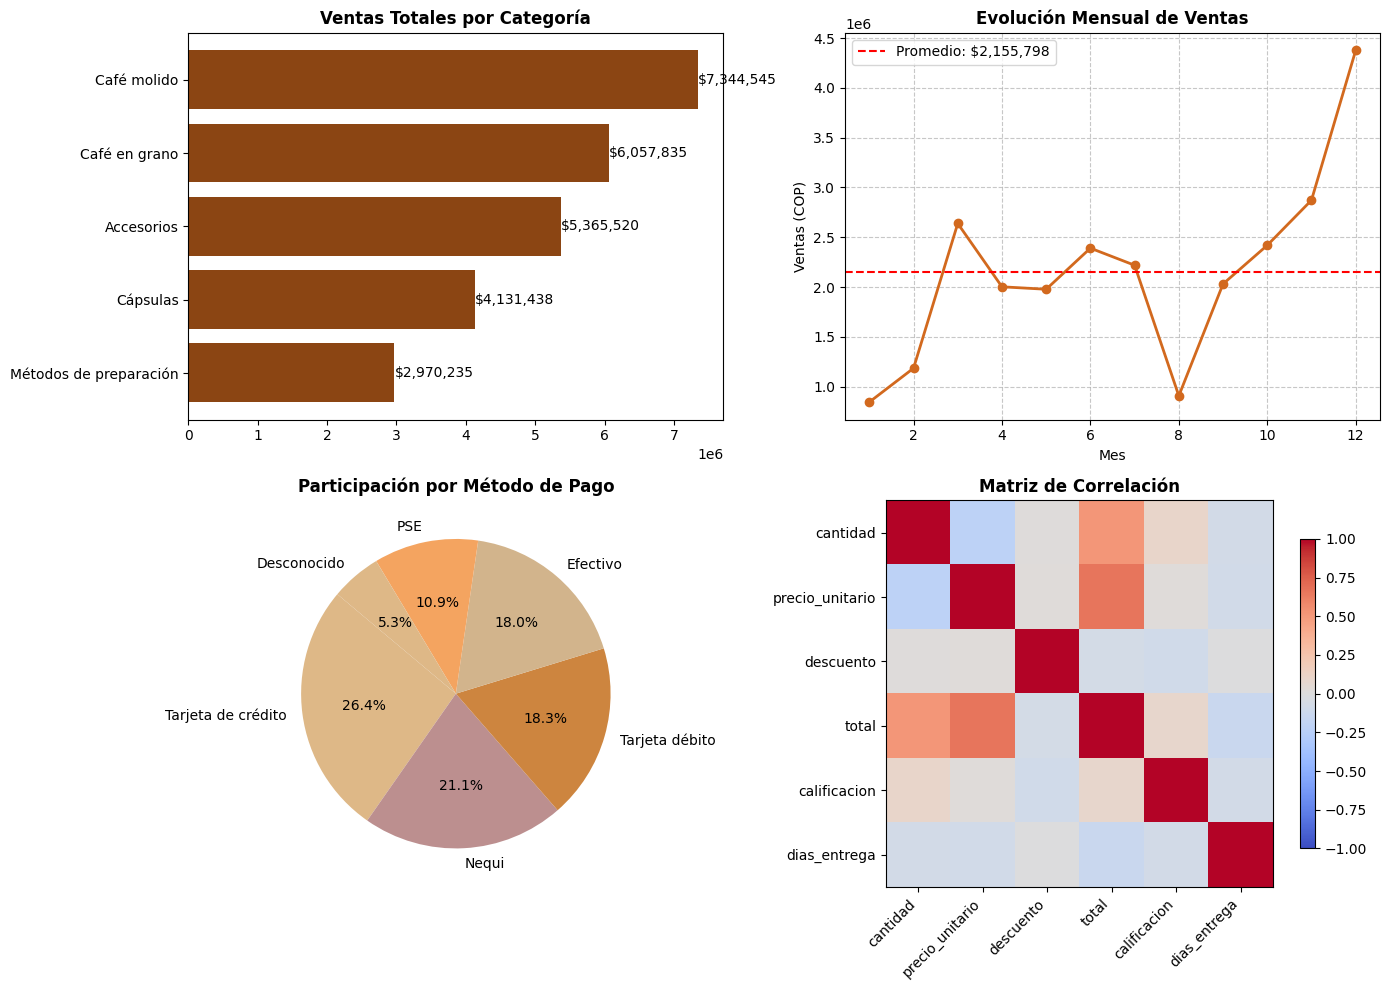

In [13]:

# 3.5 ANÁLISIS VISUAL Y TOMA DE DECISIONES
# 1. Impacto del ETL en la decisión (Ventas por sede: Crudo vs Limpio)
ventas_crudo = df_raw.groupby('sede')['total'].sum()
ventas_limpio = df_clean.groupby('sede')['total'].sum()
comparativa_ventas = pd.DataFrame({'Ventas_Crudo': ventas_crudo, 'Ventas_Limpio': ventas_limpio})
display(comparativa_ventas)

# Gráfica comparativa lado a lado
comparativa_ventas.plot(kind='bar', figsize=(10, 5), color=['#A0522D', '#228B22'])
plt.title('Impacto del ETL: Ventas Totales por Sede (Crudo vs. Limpio)', fontweight='bold')
plt.xlabel('Sede')
plt.ylabel('Ventas Totales (COP)')
plt.xticks(rotation=0)
plt.legend(['Datos Crudos (Sucios)', 'Datos Limpios'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Gráficas analíticas con Matplotlib
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Gráfica A: Ventas por categoría
ventas_cat = df_clean.groupby('categoria')['total'].sum().sort_values()
bars = axs[0, 0].barh(ventas_cat.index, ventas_cat.values, color='#8B4513')
axs[0, 0].set_title('Ventas Totales por Categoría', fontweight='bold')
axs[0, 0].bar_label(bars, fmt='${:,.0f}')

# Gráfica B: Evolución mensual de ventas con línea de promedio
ventas_mes = df_clean.groupby('mes')['total'].sum()
axs[0, 1].plot(ventas_mes.index, ventas_mes.values, marker='o', color='#D2691E', linewidth=2)
axs[0, 1].axhline(ventas_mes.mean(), color='red', linestyle='--', label=f'Promedio: ${ventas_mes.mean():,.0f}')
axs[0, 1].set_title('Evolución Mensual de Ventas', fontweight='bold')
axs[0, 1].set_xlabel('Mes')
axs[0, 1].set_ylabel('Ventas (COP)')
axs[0, 1].legend()
axs[0, 1].grid(True, linestyle='--', alpha=0.7)

# Gráfica C: Participación de métodos de pago
pago_counts = df_clean['metodo_pago'].value_counts()
axs[1, 0].pie(pago_counts.values, labels=pago_counts.index, autopct='%1.1f%%', startangle=140, colors=['#DEB887', '#BC8F8F', '#CD853F', '#D2B48C', '#F4A460'])
axs[1, 0].set_title('Participación por Método de Pago', fontweight='bold')

# Gráfica D: Matriz de correlación de variables numéricas
num_cols = ['cantidad', 'precio_unitario', 'descuento', 'total', 'calificacion', 'dias_entrega']
corr_matrix = df_clean[num_cols].corr()
cax = axs[1, 1].imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
axs[1, 1].set_xticks(range(len(num_cols)))
axs[1, 1].set_yticks(range(len(num_cols)))
axs[1, 1].set_xticklabels(num_cols, rotation=45, ha='right')
axs[1, 1].set_yticklabels(num_cols)
axs[1, 1].set_title('Matriz de Correlación', fontweight='bold')
fig.colorbar(cax, ax=axs[1, 1], shrink=0.8)

plt.tight_layout()
plt.show()

Recomendaciones Estratégicas para la Gerencia de Café Aroma Andino en 2026

1. Optimización logística y refuerzo en entregas: Dado que se identificaron relaciones críticas entre los tiempos de entrega prolongados y la insatisfacción del cliente, se recomienda establecer un límite estricto de 3 días para despachos fuera de tienda física y renegociar con los operadores logísticos en las sedes con mayor índice de retrasos, garantizando la fidelización del consumidor de café especial.

2. Estrategia comercial enfocada en canales y categorías líderes: A partir de los resultados del análisis visual (donde la tienda física y el canal web concentran el mayor volumen, y categorías como el café molido y en grano lideran las ventas), se sugiere destinar el presupuesto de marketing de 2026 a campañas digitales dirigidas al e-commerce y potenciar la exhibición de café en grano en los puntos físicos.

3. Campañas estacionales planificadas: Aprovechando los picos de ventas evidenciados en la evolución mensual, la gerencia debe anticipar inventarios y personal de refuerzo en las temporadas de mayor demanda (como los meses de cierre de año), evitando desabastecimientos y maximizando los ingresos de la compañía.

4. Recomendación para mejorar la captura de datos en sedes: Para evitar los errores de digitación, duplicidad y formatos inconsistentes encontrados en el dataset crudo (como variaciones en nombres de sedes o precios atípicos), se recomienda implementar un sistema centralizado de punto de venta (POS) con campos validados, menús desplegables obligatorios y restricciones de ingreso numérico que impidan registrar caracteres especiales o valores negativos.

Preguntas de Reflexión (Para el apartado de conclusiones)

¿Qué ventajas tiene imputar con la mediana por grupo frente a la media global?
La mediana por grupo (por ejemplo, por producto o por sede) preserva de forma mucho más fiel la variabilidad y las características específicas de cada subconjunto de datos, evitando distorsiones que genera la media global, la cual es altamente sensible a valores atípicos (outliers) y no considera las particularidades del negocio local.


¿Qué sesgo introduce etiquetar un valor como "Desconocido"?
Introduce un sesgo de agrupación o concentración artificial, inflando una categoría residual que no aporta información real sobre el comportamiento del cliente o de la operación, lo cual puede subestimar las métricas de participación de mercado o enmascarar problemas de captura de información si no se maneja con precaución.


¿En qué casos es preferible eliminar registros en lugar de imputarlos?
Es preferible eliminar registros cuando el volumen de datos faltantes o erróneos compromete variables críticas e irreuperables para el análisis (como la fecha exacta del pedido o la clave primaria id_pedido), o cuando la imputación pueda introducir un sesgo estadístico tan severo que distorsione por completo las conclusiones gerenciales y la toma de decisiones.   